In [1]:
import os
from shapely.geometry import Polygon
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.draw import polygon
import tifffile
import seaborn as sns



In [83]:

sample = "ckd"
if sample == "aki":
    sample_n = '3782'
elif sample == "ref":
    sample_n = 'KPMP_038'
elif sample == "ckd":
    sample_n = '3990'


file_path = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected\{sample}_cell_boundaries.parquet"
metadata_path = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected\_metadata.csv"

metadata_list = [
'low_quality',
"POD",
"PT",
"CNT",
"DCT",
"TAL",
"DTL",
"ATL",
"IC",
"altPOD",
"altPT",
"altCNT",
"altDCT",
"altTAL",
"altDTL",
"altATL",
"altIC",
"PC",
"PEC",
"MD",
"EC",
"EC-GC",
"FIB",
"infFIB",
"pvFIB",
"aFIB",
"B",
"DC",
"MON",
"N",
"NK",
"PL",
"T",
"MAC",
"resMAC",
"moMAC",
"moMAC-INF",
"MAST",
"Lymphoid",
"Myeloid",
"NEU",
"SC/NEU",
"MC",
"MYOF",
"REN",
"VSM/P",
"unassigned"
]

name = os.path.basename(file_path).split("_")[0]
output_dir = os.path.dirname(metadata_path)
palette = sns.color_palette("husl", len(metadata_list))

def parse_color(val, default=(128, 128, 128)):
    """
    Parses a color value (hex string, float RGB tuple, or integer RGB tuple)
    and returns a standard (R, G, B) integer tuple in the range [0, 255].
    """
    if val is None:
        return default
    if isinstance(val, str):
        # Handle hex strings (e.g. '#FF0000' or 'FF0000')
        hex_str = val.lstrip('#')
        try:
            if len(hex_str) == 6:
                return tuple(int(hex_str[i:i+2], 16) for i in (0, 2, 4))
            elif len(hex_str) == 3:
                return tuple(int(hex_str[i]*2, 16) for i in (0, 1, 2))
        except ValueError:
            pass
    elif isinstance(val, (tuple, list, np.ndarray)) and len(val) == 3:
        # Check if values are floats in range [0.0, 1.0] (e.g. from seaborn palettes)
        if all(isinstance(x, (float, np.floating)) for x in val) and all(0.0 <= x <= 1.0 for x in val):
            if any(x > 1.0 for x in val):
                return tuple(int(x) for x in val)
            return tuple(int(round(x * 255)) for x in val)
        return tuple(int(x) for x in val)
    return default


In [ ]:
import sys
from pathlib import Path
import cv2

sys.path.insert(0, str(Path.cwd().parent.parent))
from core.roi_coordinate_transformer import CellDataMapper, apply_roi_transform_from_json


# Process multiple ROIs in a loop
transform_base_dir = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected"
transform_pattern = f"protein-result_transform.i2r.json"

cell_seg_csv = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected\{sample}_cell_segmentation.csv"
cell_seg_df = pd.read_csv(cell_seg_csv)
if "Unnamed: 0" in cell_seg_df.columns:
    cell_seg_df = cell_seg_df.drop(columns=["Unnamed: 0"])

# Define your color mapping dictionary here. 
# Map each levelKID_refined cell label to an (R, G, B) tuple.
# Omitted labels will fallback to gray.

# color_dict = {
#     "POD": "#fe0000",
#     "altPOD": "#a6003e",
#     "PEC": "#803e4c",
#     "MC": "#cbb2b9",
#     "EC-GC": "#f87197",

#     "PT": "#0aff05",
#     "altPT": "#5b8313",

#     "DTL": "#2ca559",
#     "altDTL": "#55f17b",

#     "ATL": "#669b90",
#     "altATL": "#bfdad4",

#     "TAL": "#56ebd3",
#     "altTAL": "#1e5c4a",



# }

# color_dict = {
#     "POD": "#bc0542",
#     "altPOD": "#bc0542",

#     "PEC": "#fd5917",
#     "MC": "#fd5917",
#     "EC-GC": "#fd5917",

#     "PT": "#fbbd13",
#     "altPT": "#fbbd13",

#     "DTL": "#e7ad79",
#     "altDTL": "#e7ad79",

#     "ATL": "#873c24",
#     "altATL": "#873c24",

#     "TAL": "#d24ec1",
#     "altTAL": "#d24ec1",

#     "DCT":"#da73f8",
#     "altDCT":"#da73f8",
#     "MD":"#da73f8",

#     "CNT": "#841ea4",
#     "altCNT": "#841ea4",

#     "PC": "#4158b1",

#     "IC": "#b8b2f0",
#     "altIC": "#b8b2f0",

#     "FIB": "#72e5ef",
#     "pvFIB": "#72e5ef",

#     "aFIB": "#72e5ef",
#     "infFIB": "#72e5ef",
#     "MYOF": "#72e5ef",

#     "EC": "#115d52",

#     "Myeloid" : "#2f882d",
#     "MON": "#2f882d",
#     "DC": "#2f882d",
#     "MAC": "#2f882d",
#     "resMAC": "#2f882d",
#     "moMAC": "#2f882d",
#     "moMAC-INF": "#2f882d",
#     "N": "#2f882d",

#     "Lymphoid": "#5df23e",
#     "T": "#5df23e",
#     "B": "#5df23e",
#     "NK": "#5df23e",
#     "PL": "#5df23e",

#     "NEU": "#6d4c2b",
#     "SC/NEU": "#6d4c2b",

#     "REN": "#821f48",
#     "VSM/P": "#821f48",

#     "low_quality" : "#000000",
#     "unassigned": "#000000"
# }


# color_dict = {
#     # "POD": "#bc0542",
#     # "altPOD": "#bc0542",

#     # "PEC": "#fd5917",
#     # "MC": "#fd5917",
#     # "EC-GC": "#fd5917",

#     # "PT": "#fbbd13",
#     # "altPT": "#e3c60b",

#     # "DTL": "#e7ad79",
#     # "altDTL": "#e7ad79",

#     # "ATL": "#873c24",
#     # "altATL": "#873c24",

#     # "TAL": "#d24ec1",
#     # "altTAL": "#d24ec1",

#     # "DCT":"#da73f8",
#     # "altDCT":"#da73f8",
#     # "MD":"#da73f8",

#     # "CNT": "#841ea4",
#     # "altCNT": "#841ea4",

#     # "PC": "#4158b1",

#     # "IC": "#b8b2f0",
#     # "altIC": "#b8b2f0",

#     "FIB": "#72e5ef",
#     # "pvFIB": "#72e5ef",

#     "aFIB": "#4B5DC4",
#     "infFIB": "#754BC4",
#     "MYOF": "#B24BC4",

#     "EC": "#115d52",

#     "Myeloid" : "#2f882d",
#     # "MON": "#2f882d",
#     # "DC": "#2f882d",
#     # "MAC": "#2f882d",
#     # "resMAC": "#2f882d",
#     # "moMAC": "#2f882d",
#     # "moMAC-INF": "#2f882d",
#     # "N": "#2f882d",

#     "Lymphoid": "#5df23e",
#     # "T": "#5df23e",
#     # "B": "#5df23e",
#     # "NK": "#5df23e",
#     # "PL": "#5df23e",

#     # "NEU": "#6d4c2b",
#     # "SC/NEU": "#6d4c2b",

#     # "REN": "#821f48",
#     # "VSM/P": "#821f48",

#     "low_quality" : "#000000",
#     "unassigned": "#000000"
# }


color_dict = {
    "POD": "#bc0542",
    # "altPOD": "#bc0542",

    # "PEC": "#fd5917",
    # "MC": "#fd5917",
    # "EC-GC": "#fd5917",

    "PT": "#fbbd13",
    "altPT": "#e3c60b",

    # "DTL": "#e7ad79",
    # "altDTL": "#e7ad79",

    # "ATL": "#873c24",
    # "altATL": "#873c24",

    "TAL": "#d24ec1",
    "altTAL": "#dea8d3",

    "DCT":"#da73f8",
    "altDCT":"#825e8a",
    # "MD":"#da73f8",

    "CNT": "#841ea4",
    "altCNT": "#9c77a5",

    # "PC": "#4158b1",

    # "IC": "#b8b2f0",
    # "altIC": "#b8b2f0",

    # "FIB": "#72e5ef",
    # "pvFIB": "#72e5ef",

    # "aFIB": "#4B5DC4",
    # "infFIB": "#754BC4",
    # "MYOF": "#B24BC4",

    # "EC": "#115d52",

    # "Myeloid" : "#2f882d",
    # "MON": "#2f882d",
    # "DC": "#2f882d",
    # "MAC": "#2f882d",
    # "resMAC": "#2f882d",
    # "moMAC": "#2f882d",
    # "moMAC-INF": "#2f882d",
    # "N": "#2f882d",

    # "Lymphoid": "#5df23e",
    # "T": "#5df23e",
    # "B": "#5df23e",
    # "NK": "#5df23e",
    # "PL": "#5df23e",

    # "NEU": "#6d4c2b",
    # "SC/NEU": "#6d4c2b",

    # "REN": "#821f48",
    # "VSM/P": "#821f48",

    "low_quality" : "#000000",
    "unassigned": "#000000"
}
    # color_dict = dict(zip(metadata_list, palette))

parsed_color_dict = {}
for i, label in enumerate(metadata_list):
    # Look up the color in color_dict; fallback to seaborn palette if missing
    raw_color = color_dict.get(label, (28, 28, 28))
    if raw_color is None:
        raw_color = palette[i]
    parsed_color_dict[label] = parse_color(raw_color)

# Find all transformation files
transform_files = list(Path(transform_base_dir).glob(transform_pattern))
print(f"Found {len(transform_files)} transformation files for sample {sample}")

df_metadata = pd.read_csv(metadata_path)
df_metadata.rename(columns={'cell_ID': 'cell_id'}, inplace=True)  # Ensure consistent naming

# Image resolution
res = 1.3258
res_x = 1/ res
res_y = 1/ res

# Process each ROI
roi_results = {}
for transform_json in sorted(transform_files):
    # Extract roi id or use 'transformed' fallback for WSI transform files
    roi_name = transform_json.stem.split('-')[1].split('_')[0] if '-' in transform_json.stem else 'transformed'
    
    # Transform cells
    roi_cells_transformed, roi_bounds = apply_roi_transform_from_json(transform_json, cell_seg_df, clip_to_roi=False, return_roi_bounds=True, use_inverse=True)

    roi_cells_transformed_cropped = roi_cells_transformed[
        (roi_cells_transformed['x_roi'] >= 0) & 
        (roi_cells_transformed['y_roi'] >= 0) &
        (roi_cells_transformed['x_roi'] < roi_bounds['width']) &
        (roi_cells_transformed['y_roi'] < roi_bounds['height'])
    ].copy()

    cells_in_roi = roi_cells_transformed_cropped['cell_id'].unique()
    total_roi_cells = roi_cells_transformed[roi_cells_transformed['cell_id'].isin(cells_in_roi)].copy()
    total_roi_cells[['x_roi', 'y_roi']] = total_roi_cells[['x_roi', 'y_roi']].clip(lower=[0, 0], upper=[roi_bounds['width'], roi_bounds['height']], axis=1)
    total_roi_cells = total_roi_cells.merge(df_metadata, on='cell_id', how='left')
    # Flip rois vertically
    total_roi_cells['y_roi'] = roi_bounds['height'] - total_roi_cells['y_roi']

    roi_results[f"{roi_name}_cells"] = total_roi_cells

    total_roi_cells.to_parquet(os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_cells.parquet'), index=False)

    # Create mask stack and RGB image for the ROI
    mask_stack = np.zeros((len(metadata_list), roi_bounds['height'], roi_bounds['width']), dtype=np.uint8)
    rgb_image = np.zeros((roi_bounds['height'], roi_bounds['width'], 3), dtype=np.uint8)


    for label_id, group in total_roi_cells.groupby('levelKID_refined'):
        result = group.groupby('cell_id')[['x_roi', 'y_roi']].apply(lambda df: df.values).reset_index(name='coordinates')

        instances = result['coordinates'].to_list()
        
        idx = metadata_list.index(label_id)

        mask = mask_stack[idx]
        
        # Determine color (fallback to gray if omitted)
        color = parsed_color_dict.get(label_id, default_gray)
        color = tuple(int(c) for c in color)

        if len(instances) == 0:
            continue  # Skip if no instances

        for vertices in instances:
            if len(vertices) > 0:
                cv2.fillPoly(mask, [vertices], 255)
                cv2.fillPoly(rgb_image, [vertices], color)

    # tifffile.imwrite(
    #     os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_stack.tif'),
    #     mask_stack,
    #     imagej=True,
    #     resolution=(res_x, res_y),
    #     resolutionunit=1,
    #     metadata={
    #         'axes': 'ZYX',       # Stack as Z slices
    #         'Labels': metadata_list,
    #         'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
    #         'spacing': 1,  # Z spacing reuses Y pixel size
    #     },
    # )

    # Write output RGB image
    tifffile.imwrite(
        os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_rgb-collagen.tif'),
        rgb_image,
        imagej=True,
        resolution=(res_x, res_y),
        resolutionunit=1,
        photometric='rgb',
        metadata={
            'axes': 'CYX',       # RGB image
            'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
            'spacing': 1,  # Z spacing reuses Y pixel size
        },
    )

    # roi_results[f"{roi_name}_bounds"] = roi_bounds
    
    # # Identify roi_centroids for each cell in the ROI
    # roi_centroids = total_roi_cells.groupby('cell_id')[['x_roi', 'y_roi']].mean().reset_index()
    # roi_centroids.rename(columns={'x_roi': 'centroid_x', 'y_roi': 'centroid_y'}, inplace=True)
    # roi_centroids['centroid_x'] = roi_centroids['centroid_x'].astype(int)
    # roi_centroids['centroid_y'] = roi_centroids['centroid_y'].astype(int)
    # roi_centrods = roi_centroids.merge(df_metadata, on='cell_id', how='left')
    # roi_results[f"{roi_name}_centroids"] = roi_centroids

    # roi_centrods.to_parquet(os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_cell_centroids.parquet'), index=False)

    # # Get statistics
    # num_cells = len(total_roi_cells)
    # x_roi_range = (total_roi_cells['x_roi'].min(), total_roi_cells['x_roi'].max())
    # y_roi_range = (total_roi_cells['y_roi'].min(), total_roi_cells['y_roi'].max())
    
    # print(f"\n{roi_name}:")
    # print(f"  Cells: {num_cells}")
    # print(f"  x_roi range: {x_roi_range}")
    # print(f"  y_roi range: {y_roi_range}")
        
    # print(f"Created mask stack for {roi_name} with shape {mask_stack.shape}")

    # roi_results[f"{roi_name}_stats"] = {
    #     'num_cells': num_cells,
    #     'x_roi_range': x_roi_range,
    #     'y_roi_range': y_roi_range
    # }


Found 1 transformation files for sample ckd


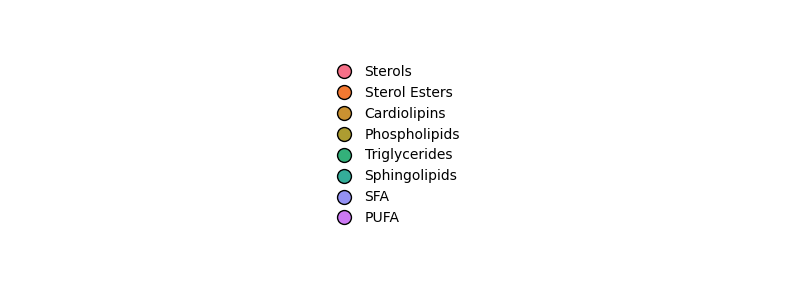

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# 1. Define your legend dictionary mapping labels to colors
# legend_dict = {
#     'POD': "#bc0542",
#     'GLOM': "#fd5917",
#     'PT': "#fbbd13",
#     "DTL": "#e7ad79",
#     "ATL": "#873c24",
#     "TAL": "#d24ec1",
#     "DCT": "#da73f8",
#     "CNT": "#841ea4",
#     "IC": "#b8b2f0",
#     "PC": "#4158b1",
#     "FIB": "#72e5ef",
#     "EC": "#115d52",
#     "Myeloid": "#2f882d",
#     "Lymphoid": "#5df23e",
#     "Stromal" : "#821f48",
#     "Neu": "#6d4c2b",

# }
# legend_dict = {
#     # "EC-GC": "#fd5917",
#     "EC": "#115d52",
#     "FIB": "#72e5ef",
        
#     "aFIB": "#4B5DC4",
#     "infFIB": "#754BC4",
#     "MYOF": "#B24BC4",



#     "Myeloid" : "#2f882d",
#     "Lymphoid": "#5df23e",

# }


# legend_dict = {
#     "POD": "#bc0542",
#     "REN": "#cc97e8",


#     "PT": "#fbbd13",
#     "altPT": "#b48000",

#     "Myeloid" : "#2f882d",
#         "N": "#3f4a3c",
#     "resMAC" : "#60603f",
#     "moMAC-INF": "#a2af9f",
#     "MON": "#066e13",
#     "DC": "#007365",



#     "Lymphoid": "#5df23e",
#     "T": "#00c7a6",
# }

# legend_dict = {
#     "Redox": "#C5E0B4",
#     "Lip/Pro": "#B4C7E7",
#     "Lip Unsat": "#2F5597",
#     "Col. Coherence": "#FFF2CC",
#     "Col. Thickness": "#FFC000"

# }


# legend_dict  = {
#     "POD": "#bc0542",

#     "PT": "#fbbd13",
#     "altPT": "#B48000",


#     "TAL": "#c16d52",
#     "altTAL": "#ffe6d6",

#     "DCT":"#ff6bca",
#     "altDCT":"#ff8098",


#     "CNT": "#841ea4",
#         "altCNT": "#9c77a5",
    
# }

legend_dict = {
    # "No Match" : "#000000",
    "Sterols" :	"#f67088",
    "Sterol Esters":	"#f37932",
    "Cardiolipins":	"#ca9131",
    "Phospholipids":	"#ad9c31",
    # "Lysophospholipids"	:"#8ea531",
    # "Diglycerides":	"#4fb031",
    "Triglycerides"	:"#33b07a",
    "Sphingolipids":	"#34ad99",
    # "Glucosylsphingolipids":	"#36abae",
    # "Dihydroceramides"	:"#38a8c5",
    # "Deoxyceramides"	:"#3ba3ec",
    "SFA"	:"#9491f4",
    "PUFA":	"#cc79f4",
    # "Carnitines"	:"#f45fe3",

}
legend_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markersize=10)
    for label, color in legend_dict.items()
]

# 3. Create a clean figure and axis canvas
fig, ax = plt.subplots(figsize=(8,3))

# 4. Generate the legend arranged into two rows (ncol)
# For 6 items, ncol=3 creates 2 rows (3 columns)
# For 4 items, ncol=2 creates 2 rows (2 columns)
leg = ax.legend(
    handles=legend_handles, 
    labels=list(legend_dict.keys()), 
    loc='center',
    ncol=len(legend_dict)//4+1 if len(legend_dict) % 2 > 0 else len(legend_dict)//8,       
    # ncol=len(legend_dict),
    frameon=False,          # Set to False if you want a transparent background
    handletextpad=0.5,
    columnspacing=1.5
)

# 5. Hide the axes completely so they do not render
ax.axis('off')

# 6. Extract the legend dimensions and save only that bounding box
fig.canvas.draw()
bbox = leg.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
plt.tight_layout()
output_dir = r"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\poster-figures"
# plt.savefig(os.path.join(output_dir, 'dyslip-legend.png'),dpi=300, transparent=True)
plt.show()



In [ ]:
df = pd.read_parquet(file_path)
df_x = df['vertex_x']
df_y = df['vertex_y']

df_metadata = pd.read_csv(metadata_path)

diff_x = np.diff(df_x)
diff_y = np.diff(df_y)

min_x = np.min(diff_x[diff_x>0])
min_y = np.min(diff_y[diff_y>0])

pad_x = 10
pad_y = 10

diff_x_rounded = np.round(diff_x / min_x)
first_x = np.round(df['vertex_x'].iloc[0])
restored_x = np.concatenate(([first_x], first_x + np.cumsum(diff_x_rounded)))
restored_x = restored_x - restored_x.min() + pad_x

diff_y_rounded = np.round(diff_y / min_y)
first_y = np.round(df['vertex_y'].iloc[0])
restored_y = np.concatenate(([first_y], first_y + np.cumsum(diff_y_rounded)))
restored_y = restored_y - restored_y.min() + pad_y

max_x = int(restored_x.max()) + 1
max_y = int(restored_y.max()) + 1

df['x'] = restored_x
df['y'] = restored_y

num_slices = len(metadata_list)
mask = np.zeros((max_y+(2*pad_y), max_x+(2*pad_x)), dtype=np.uint8)
# Pre-calculate metadata mapping for fast O(1) lookup
label_to_idx = {label: i for i, label in enumerate(metadata_list)}

# Map cell_ID to label index directly
cell_to_idx = df_metadata.set_index('cell_ID')['levelKID_refined'].map(label_to_idx).to_dict()
# Default index for "unassigned" if missing (assuming it's at the end or handle accordingly)
unassigned_idx = label_to_idx.get('unassigned', 0)

#     # Final formatting
for label_id, group in df.groupby('label_id'):
    # Get cell_id once
    cell_id = group['cell_id'].iloc[0]

    # Fast lookup
    cell_label_idx = cell_to_idx.get(cell_id, unassigned_idx)

    # Draw polygon
    r = group['y'].values
    c = group['x'].values

    rr, cc = polygon(r, c, shape=mask.shape)
    mask[rr, cc] = cell_label_idx + 1

res_x = 1 / float(min_x)
res_y = 1 / float(min_y)




tif_name = os.path.join(output_dir, f'{name}_cell_segmentation.tif')
tifffile.imwrite(
tif_name,
mask,
imagej=True,
resolution=(res_x, res_y),
resolutionunit=1,
metadata={
    'axes': 'YX',       # Stack as Z slices
    'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
    'spacing': 1,  # Z spacing reuses Y pixel size
},
)

# Save Dataframe
df.to_csv(os.path.join(output_dir, f'{name}_cell_segmentation.csv'))


# Downsample to make a large image
downsample_scale = 4
ds_restored_x = restored_x / downsample_scale
ds_restored_y = restored_y / downsample_scale

df['ds_x'] = ds_restored_x
df['ds_y'] = ds_restored_y

ds_max_x = int(ds_restored_x.max()) + 1
ds_max_y = int(ds_restored_y.max()) + 1

mask_stack = np.zeros((num_slices, ds_max_y+(2*pad_y), ds_max_x+(2*pad_x)), dtype=np.uint8)
# Final formatting
for label_id, group in df.groupby('label_id'):
    # Get cell_id once
    cell_id = group['cell_id'].iloc[0]

    # Fast lookup
    cell_label_idx = cell_to_idx.get(cell_id, unassigned_idx)

    # Draw polygon
    r = group['ds_y'].values
    c = group['ds_x'].values

    rr, cc = polygon(r, c, shape=mask_stack.shape[1:])
    mask_stack[cell_label_idx, rr, cc] = 255

stack_name = F'{os.path.basename(file_path).split("_")[0]}_cell_segmentation_stack.tif'

res_x = float(min_x * downsample_scale)
res_y = float(min_y * downsample_scale)

tifffile.imwrite(
stack_name,
mask_stack,
imagej=True,
resolution=(res_x, res_y),
resolutionunit=1,
metadata={
    'axes': 'ZYX',       # Stack as Z slices
    'Labels': metadata_list,
    'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
    'spacing': 1,  # Z spacing reuses Y pixel size
},
)

In [ ]:



roi_n = 'roi1'
tif_name = os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_n}-transformed.ome.tiff')

label_mask = tifffile.imread(tif_name)
unique_labels = np.unique(label_mask[label_mask > 0])  # Exclude background (0)

# create palette of 40+ colors for visualization
palette = sns.color_palette("husl", len(unique_labels))

mask_stack = np.zeros((len(unique_labels), label_mask.shape[0], label_mask.shape[1]), dtype=np.uint8)
for i, label in enumerate(unique_labels):
    mask_stack[i] = (label_mask == label).astype(np.uint8) * 255

# create RGB composite for visualization
rgb_stack = np.zeros((label_mask.shape[0], label_mask.shape[1], 3), dtype=np.uint8)
for i, label in enumerate(unique_labels):
    rows, cols = np.where(label_mask == label)
    rgb_stack[rows, cols, :] = (np.array(palette[i]) * 255).astype(np.uint8)

# save images
res = 0.4971847
res_x = 1/ res
res_y = 1/ res
tifffile.imwrite(
    os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_n}_stack.tif'),
    mask_stack,
    imagej=True,
    resolution=(res_x, res_y),
    resolutionunit=1,
    metadata={
        'axes': 'ZYX',       # Stack as Z slices
        'Labels': metadata_list,
        'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
        'spacing': 1,  # Z spacing reuses Y pixel size
    },
)
tifffile.imwrite(
    os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_n}_rgb.tif'),
    rgb_stack,  # Permute to YXC for ImageJ
    imagej=True,
    resolution=(res_x, res_y),
    resolutionunit=1,
    photometric='rgb',
    metadata={ 
        'axes': 'CYX',       # RGB image
        'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
    },
)

## Identify ROI cells and Extract Data

In [84]:
import sys
from pathlib import Path
import cv2


sys.path.insert(0, str(Path.cwd().parent))
from core.roi_coordinate_transformer import CellDataMapper, apply_roi_transform_from_json

bb_csv = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected\Xen24_{sample_n}-{sample}-protein-roi-masks_instance_bboxes.csv"
cell_seg_csv = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected\{sample}_cell_segmentation.csv"
bb_df = pd.read_csv(bb_csv)
if "Unnamed: 0" in bb_df.columns:
    bb_df = bb_df.drop(columns=["Unnamed: 0"])
# cell_seg_df = pd.read_csv(cell_seg_csv)
# if "Unnamed: 0" in cell_seg_df.columns:
#     cell_seg_df = cell_seg_df.drop(columns=["Unnamed: 0"])

# display(cell_seg_df.head())


# Process multiple ROIs in a loop
transform_base_dir = rf"D:\ADATA Backup\HuBMAP\HuBMAP Xenium\Xenium_data\Xen24_{sample_n}_{sample}-selected"
transform_pattern = f"{sample}_cell_segmentation-*_transform.i2r.json"

output_dir = os.path.dirname(bb_csv)

# # Image resolution
# res = 0.4971847
# res_x = 1/ res
# res_y = 1/ res


cell_seg_df = pd.read_csv(cell_seg_csv)
if "Unnamed: 0" in cell_seg_df.columns:
    cell_seg_df = cell_seg_df.drop(columns=["Unnamed: 0"])

# Define your color mapping dictionary here. 
# Map each levelKID_refined cell label to an (R, G, B) tuple.
# Omitted labels will fallback to gray.

# color_dict = {
#     "POD": "#fe0000",
#     "altPOD": "#a6003e",
#     "PEC": "#803e4c",
#     "MC": "#cbb2b9",
#     "EC-GC": "#f87197",

#     "PT": "#0aff05",
#     "altPT": "#5b8313",

#     "DTL": "#2ca559",
#     "altDTL": "#55f17b",

#     "ATL": "#669b90",
#     "altATL": "#bfdad4",

#     "TAL": "#56ebd3",
#     "altTAL": "#1e5c4a",



# }

# color_dict = {
#     "POD": "#bc0542",
#     # "altPOD": "#bc0542",

#     # "PEC": "#fd5917",
#     # "MC": "#fd5917",
#     # "EC-GC": "#fd5917",

#     "PT": "#fbbd13",
#     "altPT": "#b48000",

#     # "DTL": "#e7ad79",
#     # "altDTL": "#e7ad79",

#     # "ATL": "#873c24",
#     # "altATL": "#873c24",

#     # "TAL": "#d24ec1",
#     # "altTAL": "#d24ec1",

#     # "DCT":"#da73f8",
#     # "altDCT":"#da73f8",
#     # "MD":"#da73f8",

#     # "CNT": "#841ea4",
#     # "altCNT": "#841ea4",

#     # "PC": "#4158b1",

#     # "IC": "#b8b2f0",
#     # "altIC": "#b8b2f0",

#     # "FIB": "#72e5ef",
#     # "pvFIB": "#72e5ef",

#     # "aFIB": "#72e5ef",
#     # "infFIB": "#72e5ef",
#     # "MYOF": "#72e5ef",

#     # "EC": "#115d52",

#     "Myeloid" : "#2f882d",
#     "resMAC" : "#60603f",
#     "moMAC-INF": "#a2af9f",
#     "MON": "#066e13",
#     "DC": "#007365",
#     "N": "#3f4a3c",
#     "Lymphoid": "#5df23e",
#     "T": "#00c7a6",
    
#     # "B": "#5df23e",
#     # "NK": "#5df23e",
#     # "PL": "#5df23e",

#     # "NEU": "#6d4c2b",
#     # "SC/NEU": "#6d4c2b",

#     "REN": "#cc97e8",
#     # "VSM/P": "#821f48",

#     "low_quality" : "#000000",
#     "unassigned": "#000000"
# }

color_dict = {
    "POD": "#bc0542",
    # "altPOD": "#bc0542",

    # "PEC": "#fd5917",
    # "MC": "#fd5917",
    # "EC-GC": "#fd5917",

    "PT": "#fbbd13",
    "altPT": "#B48000",

    # "DTL": "#e7ad79",
    # "altDTL": "#e7ad79",

    # "ATL": "#873c24",
    # "altATL": "#873c24",

    "TAL": "#c16d52",
    "altTAL": "#ffe6d6",

    "DCT":"#ff6bca",
    "altDCT":"#ff8098",
    # "MD":"#da73f8",

    "CNT": "#841ea4",
    "altCNT": "#9c77a5",

    # "PC": "#4158b1",

    # "IC": "#b8b2f0",
    # "altIC": "#b8b2f0",

    # "FIB": "#72e5ef",
    # "pvFIB": "#72e5ef",

    # "aFIB": "#4B5DC4",
    # "infFIB": "#754BC4",
    # "MYOF": "#B24BC4",

    # "EC": "#115d52",

    # "Myeloid" : "#2f882d",
    # "MON": "#2f882d",
    # "DC": "#2f882d",
    # "MAC": "#2f882d",
    # "resMAC": "#2f882d",
    # "moMAC": "#2f882d",
    # "moMAC-INF": "#2f882d",
    # "N": "#2f882d",

    # "Lymphoid": "#5df23e",
    # "T": "#5df23e",
    # "B": "#5df23e",
    # "NK": "#5df23e",
    # "PL": "#5df23e",

    # "NEU": "#6d4c2b",
    # "SC/NEU": "#6d4c2b",

    # "REN": "#821f48",
    # "VSM/P": "#821f48",

    "low_quality" : "#000000",
    "unassigned": "#000000"
}
  
    # color_dict = dict(zip(metadata_list, palette))

parsed_color_dict = {}
for i, label in enumerate(metadata_list):
    # Look up the color in color_dict; fallback to seaborn palette if missing
    raw_color = color_dict.get(label, (28, 28, 28))
    if raw_color is None:
        raw_color = palette[i]
    parsed_color_dict[label] = parse_color(raw_color)

# Find all transformation files
transform_files = list(Path(transform_base_dir).glob(transform_pattern))
print(f"Found {len(transform_files)} transformation files for sample {sample}")

df_metadata = pd.read_csv(metadata_path)
df_metadata.rename(columns={'cell_ID': 'cell_id'}, inplace=True)  # Ensure consistent naming

# Image resolution
res = 1.3258
res_x = 1/ res
res_y = 1/ res

# Process each ROI
roi_results = {}
for transform_json in sorted(transform_files):
    # Extract roi id or use 'transformed' fallback for WSI transform files
    roi_name = transform_json.stem.split('-')[1].split('_')[0] if '-' in transform_json.stem else 'transformed'
    
    # Transform cells
    roi_cells_transformed, roi_bounds = apply_roi_transform_from_json(transform_json, cell_seg_df, clip_to_roi=False, return_roi_bounds=True, use_inverse=False)

    roi_cells_transformed_cropped = roi_cells_transformed[
        (roi_cells_transformed['x_roi'] >= 0) & 
        (roi_cells_transformed['y_roi'] >= 0) &
        (roi_cells_transformed['x_roi'] < roi_bounds['width']) &
        (roi_cells_transformed['y_roi'] < roi_bounds['height'])
    ].copy()

    cells_in_roi = roi_cells_transformed_cropped['cell_id'].unique()
    total_roi_cells = roi_cells_transformed[roi_cells_transformed['cell_id'].isin(cells_in_roi)].copy()
    total_roi_cells[['x_roi', 'y_roi']] = total_roi_cells[['x_roi', 'y_roi']].clip(lower=[0, 0], upper=[roi_bounds['width'], roi_bounds['height']], axis=1)
    total_roi_cells = total_roi_cells.merge(df_metadata, on='cell_id', how='left')
    # Flip rois vertically
    total_roi_cells['y_roi'] = roi_bounds['height'] - total_roi_cells['y_roi']

    roi_results[f"{roi_name}_cells"] = total_roi_cells

    total_roi_cells.to_parquet(os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_cells.parquet'), index=False)

    # Create mask stack and RGB image for the ROI
    mask_stack = np.zeros((len(metadata_list), roi_bounds['height'], roi_bounds['width']), dtype=np.uint8)
    # rgb_image = np.zeros((roi_bounds['height'], roi_bounds['width'], 3), dtype=np.uint8)
    rgb_image = np.full((roi_bounds['height'], roi_bounds['width'], 3), 0, dtype=np.uint8)

    default_gray = (128, 128, 128)

    for label_id, group in total_roi_cells.groupby('levelKID_refined'):
        if label_id in ['unassigned', 'low_quality']:
            continue

        result = group.groupby('cell_id')[['x_roi', 'y_roi']].apply(lambda df: df.values).reset_index(name='coordinates')

        instances = result['coordinates'].to_list()
        
        idx = metadata_list.index(label_id)

        mask = mask_stack[idx]
        
        # Determine color (fallback to gray if omitted)
        color = parsed_color_dict.get(label_id, default_gray)
        color = tuple(int(c) for c in color)

        if len(instances) == 0:
            continue  # Skip if no instances

        for vertices in instances:
            if len(vertices) > 0:
                cv2.fillPoly(mask, [vertices], 255)
                cv2.fillPoly(rgb_image, [vertices], color)

    # tifffile.imwrite(
    #     os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_stack.tif'),
    #     mask_stack,
    #     imagej=True,
    #     resolution=(res_x, res_y),
    #     resolutionunit=1,
    #     metadata={
    #         'axes': 'ZYX',       # Stack as Z slices
    #         'Labels': metadata_list,
    #         'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
    #         'spacing': 1,  # Z spacing reuses Y pixel size
    #     },
    # )

    # Write output RGB image
    tifffile.imwrite(
        os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_rgb-dyslip.tif'),
        rgb_image,
        imagej=True,
        resolution=(res_x, res_y),
        resolutionunit=1,
        photometric='rgb',
        metadata={
            'axes': 'CYX',       # RGB image
            'unit':  'micron',     # Physical unit string (e.g. 'um', 'micron')
            'spacing': 1,  # Z spacing reuses Y pixel size
        },
    )



    # roi_results[f"{roi_name}_bounds"] = roi_bounds
    
    # # Identify roi_centroids for each cell in the ROI
    # roi_centroids = total_roi_cells.groupby('cell_id')[['x_roi', 'y_roi']].mean().reset_index()
    # roi_centroids.rename(columns={'x_roi': 'centroid_x', 'y_roi': 'centroid_y'}, inplace=True)
    # roi_centroids['centroid_x'] = roi_centroids['centroid_x'].astype(int)
    # roi_centroids['centroid_y'] = roi_centroids['centroid_y'].astype(int)
    # roi_centrods = roi_centroids.merge(df_metadata, on='cell_id', how='left')
    # roi_results[f"{roi_name}_centroids"] = roi_centroids

    # roi_centrods.to_parquet(os.path.join(output_dir, f'{sample}_cell_segmentation-{roi_name}_cell_centroids.parquet'), index=False)

    # # Get statistics
    # num_cells = len(total_roi_cells)
    # x_roi_range = (total_roi_cells['x_roi'].min(), total_roi_cells['x_roi'].max())
    # y_roi_range = (total_roi_cells['y_roi'].min(), total_roi_cells['y_roi'].max())
    
    # print(f"\n{roi_name}:")
    # print(f"  Cells: {num_cells}")
    # print(f"  x_roi range: {x_roi_range}")
    # print(f"  y_roi range: {y_roi_range}")
        
    # print(f"Created mask stack for {roi_name} with shape {mask_stack.shape}")

    # roi_results[f"{roi_name}_stats"] = {
    #     'num_cells': num_cells,
    #     'x_roi_range': x_roi_range,
    #     'y_roi_range': y_roi_range
    # }


Found 2 transformation files for sample ckd


In [ ]:
roi = 'roi2'
roi_cells = roi_results.get(f'{roi}_cells')
roi_bounds = roi_results.get(f'{roi}_bounds')

# Display visually to confirm cropping
plt.figure(figsize=(roi_bounds['width']//200, roi_bounds['height']//200))
plt.scatter(roi_cells['x_roi'], roi_cells['y_roi'], s=1, alpha=0.5)
plt.title(f"Transformed and Cropped Cell Coordinates for {sample} {roi_name}")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.show()

## Generate bounding boxes from masked images

In [ ]:
from scipy import ndimage as ndi
import tifffile
import pandas as pd
import os

img_path = r"C:\Users\jvill\Documents\integrated_pipeline\VISIUM\binary_masks\S21-K21_198_3\HSI rois\S21-K21_198_3-ROI-Regions-transformed.ome.tiff"

img = tifffile.imread(img_path)
labeled_img, _ = ndi.label(img)

img_names = []
ROI_names = []
X_mins = []
X_maxs = []
Y_mins = []
Y_maxs = []

for idx, region in enumerate(ndi.find_objects(labeled_img)):
    # Find bounding box of the region in the original image
    min_row, max_row = region[0].start, region[0].stop
    min_col, max_col = region[1].start, region[1].stop

    img_names.append(os.path.basename(img_path))
    ROI_names.append(f"region_{idx+1}")
    X_mins.append(min_col)
    X_maxs.append(max_col)
    Y_mins.append(min_row)
    Y_maxs.append(max_row)

data = {
    "img_name": img_names,
    "ROI_name": ROI_names,
    "X_min": X_mins,
    "X_max": X_maxs,
    "Y_min": Y_mins,
    "Y_max": Y_maxs
}
df = pd.DataFrame(data)
df.to_csv(os.path.join(os.path.dirname(img_path), f"{os.path.basename(img_path).split('.')[0]}_region_bounding_boxes.csv"), index=False)


In [ ]:
data